### Business Problem Understanding

- Our business problem is to detect fraudulent credit card transactions. Fraud transactions can cause financial losses to banks and customers. So, our objective is to use machine learning to classify transactions as genuine or fraudulent using transaction-related features like amount, merchant, transaction type, and location.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns
import warnings
warnings.simplefilter('ignore')

### Data Collection

In [36]:
df=pd.read_csv("Credit_Card_Fraud_Detection.csv")
df

,TransactionID,TransactionDate,TransactionTime,Amount,MerchantID,TransactionType,Location,IsFraud
0,0,2024-01-01,06:00:15,332.44,668,Purchase,Chicago,0
1,1,2024-01-01,19:25:36,222.74,658,Purchase,Phoenix,0
2,2,2024-01-01,14:13:58,1863.33,258,Purchase,Los Angeles,0
3,3,2024-01-02,10:37:19,1336.60,588,Purchase,Phoenix,0
4,4,2024-01-02,07:36:05,3233.99,785,Purchase,Dallas,0
...,...,...,...,...,...,...,...,...
996,996,2024-12-29,00:55:49,3217.67,997,Refund,Los Angeles,0
997,997,2024-12-29,19:27:44,4051.20,161,Purchase,Los Angeles,0
998,998,2024-12-30,16:28:20,4737.50,355,Purchase,New York,0
999,999,2024-12-30,11:20:52,1693.33,660,Purchase,Phoenix,0


### Data Understanding


TransactionID
- A unique identification number assigned to each transaction.
- It is used to identify individual transactions.

TransactionDate
- Represents the date on which the transaction occurred.
- Example: 2024-01-01

TransactionTime
- Represents the time at which the transaction occurred.
- Example: 10:30:00

Amount
- Represents the amount of money involved in the transaction.
- Example: 250.50
- It can help identify unusual or suspicious transactions.

MerchantID
- A unique identification number of the merchant or business where the transaction was made.
- It helps identify the merchant involved in the transaction.

TransactionType
- Represents the type or method of the transaction.
- Examples: Online, POS, ATM

Location
- Represents the location where the transaction took place.
- Example: Chicago, Phoenix, Dallas
- It can help identify suspicious transactions from unusual locations.

IsFraud
- This is the target column.
- It indicates whether the transaction is fraudulent or genuine.
- 0 → Genuine transaction
- 1 → Fraudulent transaction

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   TransactionID    1001 non-null   int64  
 1   TransactionDate  1001 non-null   object 
 2   TransactionTime  1001 non-null   object 
 3   Amount           1001 non-null   float64
 4   MerchantID       1001 non-null   int64  
 5   TransactionType  1001 non-null   object 
 6   Location         1001 non-null   object 
 7   IsFraud          1001 non-null   int64  
dtypes: float64(1), int64(3), object(4)
memory usage: 62.7+ KB


In [38]:
df.describe()

,TransactionID,Amount,MerchantID,IsFraud
count,1001.000000,1001.000000,1001.000000,1001.000000
mean,500.000000,2513.414925,552.502498,0.066933
std,289.108111,1463.083361,258.913349,0.250031
min,0.000000,10.940000,100.000000,0.000000
25%,250.000000,1203.400000,334.000000,0.000000
50%,500.000000,2591.020000,551.000000,0.000000
75%,750.000000,3772.570000,766.000000,0.000000
max,1000.000000,4998.570000,999.000000,1.000000


In [39]:
df.shape

(1001, 8)

In [40]:
df['IsFraud'].value_counts()

IsFraud
0    934
1     67
Name: count, dtype: int64

### EDA

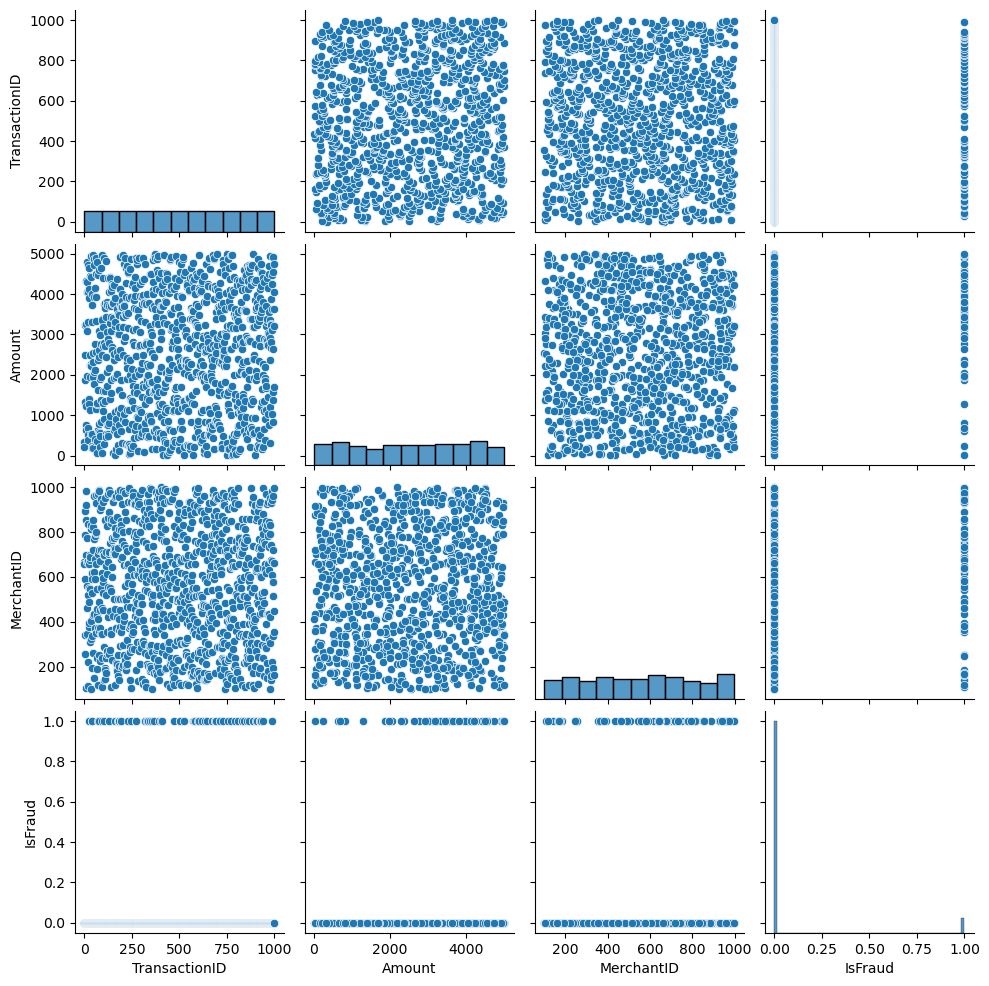

In [41]:
sns.pairplot(df)
plt.show()

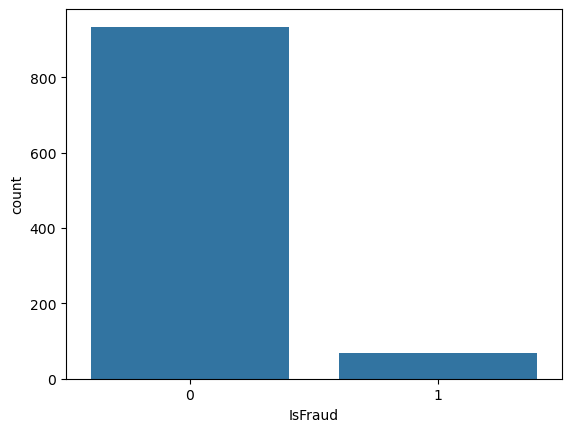

In [42]:
sns.countplot(x='IsFraud', data=df)
plt.show()

### Data Cleaning

##### Duplicates

In [43]:
df.duplicated().sum()

np.int64(0)

There are no duplicate values in the dataset

##### Finding Nan Values

In [44]:
df.isnull().sum()

TransactionID      0
TransactionDate    0
TransactionTime    0
Amount             0
MerchantID         0
TransactionType    0
Location           0
IsFraud            0
dtype: int64

There are no null values in the dataset, so no missing-value treatment is required.

### Data Wrangling

#### Encoding

In [45]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df["MerchantID"]=le.fit_transform(df["MerchantID"])
df["TransactionType"]=le.fit_transform(df["TransactionType"])
df["Location"]=le.fit_transform(df["Location"])
df

,TransactionID,TransactionDate,TransactionTime,Amount,MerchantID,TransactionType,Location,IsFraud
0,0,2024-01-01,06:00:15,332.44,377,0,1,0
1,1,2024-01-01,19:25:36,222.74,369,0,7,0
2,2,2024-01-01,14:13:58,1863.33,105,0,4,0
3,3,2024-01-02,10:37:19,1336.60,319,0,7,0
4,4,2024-01-02,07:36:05,3233.99,458,0,2,0
...,...,...,...,...,...,...,...,...
996,996,2024-12-29,00:55:49,3217.67,593,1,4,0
997,997,2024-12-29,19:27:44,4051.20,38,0,4,0
998,998,2024-12-30,16:28:20,4737.50,166,0,5,0
999,999,2024-12-30,11:20:52,1693.33,371,0,7,0


In [46]:
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])

df['Year'] = df['TransactionDate'].dt.year
df['Month'] = df['TransactionDate'].dt.month
df['Day'] = df['TransactionDate'].dt.day
df['DayOfWeek'] = df['TransactionDate'].dt.dayofweek

In [47]:
df['TransactionTime'] = pd.to_datetime(df['TransactionTime'], format='%H:%M:%S')

df['Hour'] = df['TransactionTime'].dt.hour
df['Minute'] = df['TransactionTime'].dt.minute

In [48]:
df.drop(['TransactionDate', 'TransactionTime'], axis=1, inplace=True)

In [49]:
df.columns

Index(['TransactionID', 'Amount', 'MerchantID', 'TransactionType', 'Location',
       'IsFraud', 'Year', 'Month', 'Day', 'DayOfWeek', 'Hour', 'Minute'],
      dtype='object')

In [50]:
df

,TransactionID,Amount,MerchantID,TransactionType,Location,IsFraud,Year,Month,Day,DayOfWeek,Hour,Minute
0,0,332.44,377,0,1,0,2024,1,1,0,6,0
1,1,222.74,369,0,7,0,2024,1,1,0,19,25
2,2,1863.33,105,0,4,0,2024,1,1,0,14,13
3,3,1336.60,319,0,7,0,2024,1,2,1,10,37
4,4,3233.99,458,0,2,0,2024,1,2,1,7,36
...,...,...,...,...,...,...,...,...,...,...,...,...
996,996,3217.67,593,1,4,0,2024,12,29,6,0,55
997,997,4051.20,38,0,4,0,2024,12,29,6,19,27
998,998,4737.50,166,0,5,0,2024,12,30,0,16,28
999,999,1693.33,371,0,7,0,2024,12,30,0,11,20


### X & Y

In [51]:
X = df.drop('IsFraud', axis=1)
y = df['IsFraud']

### Data Balancing

In [53]:
from sklearn.utils import resample
# Separate majority and minority classes
# Converting 'FraudFlag' to string type before filtering
df_majority = df[df['IsFraud'].astype(str).str.strip() == "0"]
df_minority = df[df['IsFraud'].astype(str).str.strip() == "1"]

# Downsample majority class and upsample the minority class
df_minority_upsampled = resample(df_minority, replace=True, n_samples=400, random_state=100)
df_majority_downsampled = resample(df_majority, replace=True, n_samples=400, random_state=100)

# Combine minority class with downsampled majority class
df = pd.concat([df_minority_upsampled, df_majority_downsampled])

# Display new class counts
df['IsFraud'].value_counts()



IsFraud
1    400
0    400
Name: count, dtype: int64

### Train-Test Split

In [54]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [55]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.fit_transform(X_test)

### Modelling

### Logistic Regression

In [56]:
#modelling
from sklearn.linear_model import LogisticRegression  #import ML algorithm
log_model=LogisticRegression()                       #save to a model
log_model.fit(X_train,y_train)  

#prediction
ypred_train=log_model.predict(X_train)
ypred_test=log_model.predict(X_test)

#accuracy
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,ypred_train))
print(accuracy_score(y_test,ypred_test))

#cross validation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(log_model,X,y,cv=5)
print(scores)
scores.mean()

0.93125
0.9402985074626866
[0.93034826 0.935      0.935      0.935      0.93      ]


np.float64(0.9330696517412935)

### KNN 

In [59]:
#Default Modelling
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_model.fit(X_train,y_train)

#Prediction
y_pred_train=knn_model.predict(X_train)
y_pred_test=knn_model.predict(X_test)

#Evaluation

#1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,y_pred_train))
print(accuracy_score(y_test,y_pred_test))

#2.Crossvalidation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(knn_model,X,y,cv=5)
scores.mean()

0.93125
0.9353233830845771


np.float64(0.9200696517412936)

### SVM

In [61]:
from sklearn.svm import SVC
model=SVC()
model.fit(X_train,y_train)

#Prediction
ypred_train=model.predict(X_train)
ypred_test=model.predict(X_test)

#Evaluation

#1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,ypred_train))
print(accuracy_score(y_test,ypred_test))

#2.Crossvalidation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(model,X,y,cv=5)
scores.mean()

0.93125
0.9402985074626866


np.float64(0.9330696517412935)

### Decision Tree

In [62]:
#DecisionTreeClassifier - with default parameters
from sklearn.tree import DecisionTreeClassifier
dt_default=DecisionTreeClassifier(random_state=0)
dt_default.fit(X_train,y_train)

#Prediction
pred_train=dt_default.predict(X_train)
base_pred=dt_default.predict(X_test)

#Evaluation

#1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print("Train accuracy:",accuracy_score(pred_train,y_train))
print("Test accuracy:",accuracy_score(base_pred,y_test))

#2.Crossvalidation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(dt_default,X,y,cv=5)
print("Cross Validation Score:",scores.mean())

Train accuracy: 1.0
Test accuracy: 0.835820895522388
Cross Validation Score: 0.7026517412935324


In [63]:
#hyperparametertuning
from sklearn.model_selection import GridSearchCV
estimator=DecisionTreeClassifier(random_state=0)
param_grid={"criterion":["gini","entropy"],"max_depth":[1,2,3,4]}
grid=GridSearchCV(estimator,param_grid,scoring='accuracy',cv=5)
grid.fit(X_train,y_train)
grid.best_params_

{'criterion': 'gini', 'max_depth': 1}

In [64]:
dt_bhp=DecisionTreeClassifier(criterion= 'gini', max_depth= 1,random_state=0)
dt_bhp.fit(X_train,y_train)

ypred_train=dt_bhp.predict(X_train)
ypred_test=dt_bhp.predict(X_test)

print("Train accuracy:",accuracy_score(ypred_train,y_train))
print("Test accuracy:",accuracy_score(ypred_test,y_test))

scores=cross_val_score(dt_bhp,X,y,cv=5)
print("Cross Validation Score:",scores.mean())

Train accuracy: 0.93125
Test accuracy: 0.9402985074626866
Cross Validation Score: 0.9330696517412935


### XGBoost

In [65]:
!pip install xgboost

In [66]:
#modelling
from xgboost import XGBClassifier
xgb_model=XGBClassifier()
xgb_model.fit(X_train,y_train)

#Prediction
y_pred_train=xgb_model.predict(X_train)
y_pred_test=xgb_model.predict(X_test)

#Evaluation

#1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print(accuracy_score(y_train,y_pred_train))
print(accuracy_score(y_test,y_pred_test))

#2.Crossvalidation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(estimator=xgb_model,X=X,y=y,cv=5)
print("Cross Validation Score:",scores.mean())

1.0
0.9303482587064676
Cross Validation Score: 0.9170746268656718


In [67]:
#hyperparametertuning
from sklearn.model_selection import GridSearchCV
estimator=XGBClassifier()
param_grid={'n_estimators':[10,20,40,100],
             'max_depth':[3,4,5],
              'gamma':[0,0.15,0.3,0.5,1]}
grid=GridSearchCV(estimator,param_grid,cv=5,scoring='accuracy')
grid.fit(X_train,y_train)
grid.best_params_

{'gamma': 0.5, 'max_depth': 3, 'n_estimators': 20}

In [68]:
#modelling
xgb_bhp=XGBClassifier(gamma = 0.5,max_depth = 3,n_estimators = 20)
xgb_bhp.fit(X_train,y_train)

#Prediction
ypred_train=xgb_bhp.predict(X_train)
predictions=xgb_bhp.predict(X_test)

#Evaluation

#1.Train & Test Accuracy
from sklearn.metrics import accuracy_score
print("Train accuracy:",accuracy_score(y_train,ypred_train))
print("Test accuracy:",accuracy_score(y_test,predictions))

#2.Crossvalidation
from sklearn.model_selection import cross_val_score
scores=cross_val_score(xgb_bhp,X,y,cv=5)
print("Cross Validation Score:",scores.mean())

Train accuracy: 0.945
Test accuracy: 0.9402985074626866
Cross Validation Score: 0.9230746268656717


In [69]:
import pandas as pd

results = pd.DataFrame({'Algorithm': ['Logistic Regression','KNN','SVM','Decision Tree','XGBoost'],
                        'Train Accuracy': [0.931,0.931,0.931,0.931,0.945],
                         'Test Accuracy': [0.940,0.935,0.940,0.940,0.940],
                         'Cross-Validation': [0.933,0.920,0.933,0.933,0.923]})

results

,Algorithm,Train Accuracy,Test Accuracy,Cross-Validation
0,Logistic Regression,0.931,0.940,0.933
1,KNN,0.931,0.935,0.920
2,SVM,0.931,0.940,0.933
3,Decision Tree,0.931,0.940,0.933
4,XGBoost,0.945,0.940,0.923


### Model Selection & Conclusion

The Credit Card Fraud Detection project successfully developed a machine learning-based system to classify transactions as genuine or fraudulent. Different machine learning algorithms, including Logistic Regression, KNN, SVM, Decision Tree, and XGBoost, were implemented and compared based on training accuracy, testing accuracy, and cross-validation score. Among the tested models, **SVM achieved the best overall performance**, with a test accuracy of **94.0%** and a cross-validation score of **93.3%**. Therefore, SVM was selected as the final model for Credit Card Fraud Detection.

### Save model

In [70]:
from joblib import dump
dump(model, 'svm_model.joblib')

['svm_model.joblib']

### Load model

In [71]:
from joblib import load
model = load('svm_model.joblib')